In [1]:
import numpy as np
import pandas as pd
import argparse
import os
from itertools import combinations
from collections import defaultdict
from upsetplot import from_memberships, UpSet
from upsetplot import plot
import matplotlib.pyplot as plt
import logging
import csv

In [2]:
# initialize dataFrames
def initialize_dfs(names):
    return {name: pd.DataFrame() for name in names}
    
# function to read csv files into dataframes
def read_csv_files(names, df_dict, base_path, columns):
    for name in names:
        file_path = os.path.join(base_path, name, "produce_final_form/final_form.csv")
        df_dict[name] = pd.read_csv(file_path, sep=',', usecols=columns)

def find_common_sequences(samples):
    combos = []
    counts = []

    # Iterate through all combinations of sample keys (categories)
    for i in range(1, len(samples) + 1):
        for combo in combinations(samples.keys(), i):
            # Find common sequences and their count
            common_seqs = set.intersection(*(set(samples[sample]) for sample in combo))
            combos.append(list(combo))  # Store the combination as a list
            counts.append(len(common_seqs))  # Store the count of common sequences

    return combos, counts

# Generate the final list format
def format_memberships(sample_sequences, result):
    formatted = []
    data = []
    
# Filter conditions: mirBase, linearfold, mirdeep2
def filter_dataframes(names, df_source, df_with_match):
    for name in names:
        df_with_match[name] = filter_any_condition_met(df_source[name])
        # df_all_zero[name] = filter_none_met(df_source[name])

def filter_any_condition_met(df):
    filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) >= 0)]
    filtered_df = filtered_df.loc[:, ['sequence', 'qseqid_count']]
    # print("filtered_df",filtered_df)
    return filtered_df

def shared_by_at_least_two(all_sequences):
    all_sets = {k: set(v) for k, v in all_sequences.items()}

    total_set = set.union(*all_sets.values())  # union
    unique_only = set()
    seen = set()

    print(f"Initial: seen={seen}, unique_only={unique_only}\n")

    for name, s in all_sets.items():
        print(f"After {name}:")
        duplicates = seen & s
        unique_only |= (s - seen)
        unique_only -= duplicates
        seen |= s
        # print(f"After {name}:")
        # print(f"  sample={s}")
        # print(f"  duplicates={duplicates}")
        # print(f"  seen={seen}")
        # print(f"  unique_only={unique_only}\n")

    shared = total_set - unique_only
    return len(total_set), len(unique_only), len(shared)

In [3]:

# define the base path for output csv files
base_path = "../../../../1st_11samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
sample_names = [
    "SRR18745680", "SRR18745681", "SRR18745682", 
    "SRR18745683", "SRR18745684", "SRR18745685",
    "SRR18745686", "SRR18745687", "SRR18745688", 
    "SRR18745689", "SRR18745690"
]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
total_num_rows = 0
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
    total_num_rows += num_rows
print("total", total_num_rows)
total_num_rows_2 = 0
for name in sample_names:
    d1 = df_all_with_match[name]
    num_rows_2 = len(d1[d1['qseqid_count'].astype(int) == 1])
    print(f"DataFrame {name} ==1 has {num_rows_2} lines.")
    total_num_rows_2 += num_rows_2
print("total", total_num_rows_2)

DataFrame SRR18745680 has 246416 lines.
DataFrame SRR18745681 has 492724 lines.
DataFrame SRR18745682 has 685138 lines.
DataFrame SRR18745683 has 230217 lines.
DataFrame SRR18745684 has 46205 lines.
DataFrame SRR18745685 has 54661 lines.
DataFrame SRR18745686 has 87874 lines.
DataFrame SRR18745687 has 58402 lines.
DataFrame SRR18745688 has 66747 lines.
DataFrame SRR18745689 has 76512 lines.
DataFrame SRR18745690 has 57006 lines.
total 2101902
DataFrame SRR18745680 ==1 has 157228 lines.
DataFrame SRR18745681 ==1 has 384228 lines.
DataFrame SRR18745682 ==1 has 497802 lines.
DataFrame SRR18745683 ==1 has 170632 lines.
DataFrame SRR18745684 ==1 has 37979 lines.
DataFrame SRR18745685 ==1 has 29241 lines.
DataFrame SRR18745686 ==1 has 67886 lines.
DataFrame SRR18745687 ==1 has 44677 lines.
DataFrame SRR18745688 ==1 has 49827 lines.
DataFrame SRR18745689 ==1 has 57042 lines.
DataFrame SRR18745690 ==1 has 44764 lines.
total 1541306


In [4]:

# define the base path for output csv files
base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
sample_names = [
    "SRR18078867", "SRR18078868", "SRR18078869", 
    "SRR18078870", "SRR18078871", "SRR18078872"
]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
total_num_rows = 0
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
    total_num_rows += num_rows
print("total", total_num_rows)
total_num_rows_2 = 0
for name in sample_names:
    d1 = df_all_with_match[name]
    num_rows_2 = len(d1[d1['qseqid_count'].astype(int) == 1])
    print(f"DataFrame {name} ==1 has {num_rows_2} lines.")
    total_num_rows_2 += num_rows_2
print("total", total_num_rows_2)


DataFrame SRR18078867 has 89985 lines.
DataFrame SRR18078868 has 59362 lines.
DataFrame SRR18078869 has 46023 lines.
DataFrame SRR18078870 has 85316 lines.
DataFrame SRR18078871 has 46533 lines.
DataFrame SRR18078872 has 60844 lines.
total 388063
DataFrame SRR18078867 ==1 has 10133 lines.
DataFrame SRR18078868 ==1 has 7939 lines.
DataFrame SRR18078869 ==1 has 7315 lines.
DataFrame SRR18078870 ==1 has 23307 lines.
DataFrame SRR18078871 ==1 has 9182 lines.
DataFrame SRR18078872 ==1 has 14897 lines.
total 72773


In [5]:

# define the base path for output csv files
#base_path = "../../../../2nd_6samples_output"
base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
sample_names = [
    "SRR20723831", "SRR20723832", "SRR20723833"
]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
total_num_rows = 0
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
    total_num_rows += num_rows
print("total", total_num_rows)
total_num_rows_2 = 0
for name in sample_names:
    d1 = df_all_with_match[name]
    num_rows_2 = len(d1[d1['qseqid_count'].astype(int) == 1])
    print(f"DataFrame {name} ==1 has {num_rows_2} lines.")
    total_num_rows_2 += num_rows_2
print("total", total_num_rows_2)

DataFrame SRR20723831 has 2560760 lines.
DataFrame SRR20723832 has 2457237 lines.
DataFrame SRR20723833 has 2668933 lines.
total 7686930
DataFrame SRR20723831 ==1 has 1349494 lines.
DataFrame SRR20723832 ==1 has 1300596 lines.
DataFrame SRR20723833 ==1 has 1448778 lines.
total 4098868


In [6]:

# define the base path for output csv files
#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
sample_names = [
    "SRR25896993", "SRR25896994", "SRR25896995"
]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
total_num_rows = 0
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
    total_num_rows += num_rows
print("total", total_num_rows)
total_num_rows_2 = 0
for name in sample_names:
    d1 = df_all_with_match[name]
    num_rows_2 = len(d1[d1['qseqid_count'].astype(int) == 1])
    print(f"DataFrame {name} ==1 has {num_rows_2} lines.")
    total_num_rows_2 += num_rows_2
print("total", total_num_rows_2)


DataFrame SRR25896993 has 408670 lines.
DataFrame SRR25896994 has 409256 lines.
DataFrame SRR25896995 has 453399 lines.
total 1271325
DataFrame SRR25896993 ==1 has 77642 lines.
DataFrame SRR25896994 ==1 has 75298 lines.
DataFrame SRR25896995 ==1 has 86537 lines.
total 239477


In [7]:
# define the base path for output csv files
#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
base_path = "../../../../5th_9samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset5
sample_names = [
                    "SRR8195524", "SRR8195525", "SRR8195526", "SRR8195527", "SRR8195528", "SRR8195529", "SRR8195530", "SRR8195531", "SRR8195532"
               ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
total_num_rows = 0
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
    total_num_rows += num_rows
print("total", total_num_rows)
total_num_rows_2 = 0
for name in sample_names:
    d1 = df_all_with_match[name]
    num_rows_2 = len(d1[d1['qseqid_count'].astype(int) == 1])
    print(f"DataFrame {name} ==1 has {num_rows_2} lines.")
    total_num_rows_2 += num_rows_2
print("total", total_num_rows_2)


DataFrame SRR8195524 has 1151531 lines.
DataFrame SRR8195525 has 33096 lines.
DataFrame SRR8195526 has 1040781 lines.
DataFrame SRR8195527 has 1122635 lines.
DataFrame SRR8195528 has 546953 lines.
DataFrame SRR8195529 has 1128618 lines.
DataFrame SRR8195530 has 1474716 lines.
DataFrame SRR8195531 has 1411724 lines.
DataFrame SRR8195532 has 1111881 lines.
total 9021935
DataFrame SRR8195524 ==1 has 890459 lines.
DataFrame SRR8195525 ==1 has 17762 lines.
DataFrame SRR8195526 ==1 has 775053 lines.
DataFrame SRR8195527 ==1 has 853330 lines.
DataFrame SRR8195528 ==1 has 454441 lines.
DataFrame SRR8195529 ==1 has 867221 lines.
DataFrame SRR8195530 ==1 has 1093155 lines.
DataFrame SRR8195531 ==1 has 1050160 lines.
DataFrame SRR8195532 ==1 has 879453 lines.
total 6881034


In [8]:
# define the base path for output csv files
#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
base_path = "../../../../6th_8samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
# #dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
sample_names = ["ERR629132","ERR629133","ERR629134",
                "ERR629135","ERR629136","ERR629137",
                "ERR629138","ERR629139"
                    
                ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
total_num_rows = 0
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
    total_num_rows += num_rows
print("total", total_num_rows)
total_num_rows_2 = 0
for name in sample_names:
    d1 = df_all_with_match[name]
    num_rows_2 = len(d1[d1['qseqid_count'].astype(int) == 1])
    print(f"DataFrame {name} ==1 has {num_rows_2} lines.")
    total_num_rows_2 += num_rows_2
print("total", total_num_rows_2)


DataFrame ERR629132 has 327854 lines.
DataFrame ERR629133 has 250026 lines.
DataFrame ERR629134 has 377666 lines.
DataFrame ERR629135 has 272937 lines.
DataFrame ERR629136 has 499036 lines.
DataFrame ERR629137 has 516161 lines.
DataFrame ERR629138 has 425015 lines.
DataFrame ERR629139 has 291297 lines.
total 2959992
DataFrame ERR629132 ==1 has 212018 lines.
DataFrame ERR629133 ==1 has 155866 lines.
DataFrame ERR629134 ==1 has 242932 lines.
DataFrame ERR629135 ==1 has 172195 lines.
DataFrame ERR629136 ==1 has 298300 lines.
DataFrame ERR629137 ==1 has 330729 lines.
DataFrame ERR629138 ==1 has 271000 lines.
DataFrame ERR629139 ==1 has 193221 lines.
total 1876261


In [9]:
#???
# define the base path for output csv files
#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
sample_names = [
    "DRR037104","DRR037108","DRR037112"
]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
total_num_rows = 0
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
    total_num_rows += num_rows
print("total", total_num_rows)
total_num_rows_2 = 0
for name in sample_names:
    d1 = df_all_with_match[name]
    num_rows_2 = len(d1[d1['qseqid_count'].astype(int) == 1])
    print(f"DataFrame {name} ==1 has {num_rows_2} lines.")
    total_num_rows_2 += num_rows_2
print("total", total_num_rows_2)

DataFrame DRR037104 has 1002563 lines.
DataFrame DRR037108 has 881416 lines.
DataFrame DRR037112 has 953170 lines.
total 2837149
DataFrame DRR037104 ==1 has 663332 lines.
DataFrame DRR037108 ==1 has 494026 lines.
DataFrame DRR037112 ==1 has 538982 lines.
total 1696340


In [10]:

# define the base path for output csv files
#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
base_path = "../../../../8th_2samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
sample_names = [
    "SRR1638859", "SRR1638860"
]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
total_num_rows = 0
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
    total_num_rows += num_rows
print("total", total_num_rows)
total_num_rows_2 = 0
for name in sample_names:
    d1 = df_all_with_match[name]
    num_rows_2 = len(d1[d1['qseqid_count'].astype(int) == 1])
    print(f"DataFrame {name} ==1 has {num_rows_2} lines.")
    total_num_rows_2 += num_rows_2
print("total", total_num_rows_2)


DataFrame SRR1638859 has 677700 lines.
DataFrame SRR1638860 has 323802 lines.
total 1001502
DataFrame SRR1638859 ==1 has 405389 lines.
DataFrame SRR1638860 ==1 has 216446 lines.
total 621835


In [11]:

# define the base path for output csv files
#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
base_path = "../../../../9th_12samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
# #dataset9
sample_names = [
    "SRR1295645", "SRR1295827","SRR1295840","SRR1295841","SRR1295843","SRR1295844",
    "SRR1295950","SRR1295974","SRR1295975","SRR1295978","SRR1295979"
]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
total_num_rows = 0
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
    total_num_rows += num_rows
print("total", total_num_rows)
total_num_rows_2 = 0
for name in sample_names:
    d1 = df_all_with_match[name]
    num_rows_2 = len(d1[d1['qseqid_count'].astype(int) == 1])
    print(f"DataFrame {name} ==1 has {num_rows_2} lines.")
    total_num_rows_2 += num_rows_2
print("total", total_num_rows_2)


DataFrame SRR1295645 has 192305 lines.
DataFrame SRR1295827 has 35638 lines.
DataFrame SRR1295840 has 273056 lines.
DataFrame SRR1295841 has 54291 lines.
DataFrame SRR1295843 has 641097 lines.
DataFrame SRR1295844 has 4995 lines.
DataFrame SRR1295950 has 2374 lines.
DataFrame SRR1295974 has 103465 lines.
DataFrame SRR1295975 has 16091 lines.
DataFrame SRR1295978 has 505618 lines.
DataFrame SRR1295979 has 90074 lines.
total 1919004
DataFrame SRR1295645 ==1 has 129089 lines.
DataFrame SRR1295827 ==1 has 25740 lines.
DataFrame SRR1295840 ==1 has 211143 lines.
DataFrame SRR1295841 ==1 has 43030 lines.
DataFrame SRR1295843 ==1 has 420734 lines.
DataFrame SRR1295844 ==1 has 4068 lines.
DataFrame SRR1295950 ==1 has 2205 lines.
DataFrame SRR1295974 ==1 has 73025 lines.
DataFrame SRR1295975 ==1 has 6982 lines.
DataFrame SRR1295978 ==1 has 384309 lines.
DataFrame SRR1295979 ==1 has 51120 lines.
total 1351445


In [12]:

# define the base path for output csv files
#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
#base_path = "../../../../9th_12samples_output"
base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
# #dataset9
# sample_names = [
#     "SRR1295645", "SRR1295827","SRR1295840","SRR1295841","SRR1295843","SRR1295844",
#     "SRR1295950","SRR1295974","SRR1295975","SRR1295977","SRR1295978","SRR1295979"
# ]
#dataset10
sample_names = [
    "SRR943111", "SRR943112"
]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
total_num_rows = 0
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
    total_num_rows += num_rows
print("total", total_num_rows)
total_num_rows_2 = 0
for name in sample_names:
    d1 = df_all_with_match[name]
    num_rows_2 = len(d1[d1['qseqid_count'].astype(int) == 1])
    print(f"DataFrame {name} ==1 has {num_rows_2} lines.")
    total_num_rows_2 += num_rows_2
print("total", total_num_rows_2)

DataFrame SRR943111 has 230504 lines.
DataFrame SRR943112 has 199534 lines.
total 430038
DataFrame SRR943111 ==1 has 111361 lines.
DataFrame SRR943112 ==1 has 87198 lines.
total 198559


In [13]:

# define the base path for output csv files
#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
#base_path = "../../../../9th_12samples_output"
# base_path = "../../../../10th_2samples_output"
base_path = "../../../../11th_3samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
# #dataset9
# sample_names = [
#     "SRR1295645", "SRR1295827","SRR1295840","SRR1295841","SRR1295843","SRR1295844",
#     "SRR1295950","SRR1295974","SRR1295975","SRR1295977","SRR1295978","SRR1295979"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
sample_names = [
    "SRR684065", "SRR684066","SRR684086"
]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
total_num_rows = 0
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
    total_num_rows += num_rows
print("total", total_num_rows)
total_num_rows_2 = 0
for name in sample_names:
    d1 = df_all_with_match[name]
    num_rows_2 = len(d1[d1['qseqid_count'].astype(int) == 1])
    print(f"DataFrame {name} ==1 has {num_rows_2} lines.")
    total_num_rows_2 += num_rows_2
print("total", total_num_rows_2)


DataFrame SRR684065 has 17520 lines.
DataFrame SRR684066 has 29199 lines.
DataFrame SRR684086 has 23791 lines.
total 70510
DataFrame SRR684065 ==1 has 13456 lines.
DataFrame SRR684066 ==1 has 21194 lines.
DataFrame SRR684086 ==1 has 18225 lines.
total 52875


In [14]:

# define the base path for output csv files
#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
# base_path = "../../../../9th_12samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
base_path = "../../../../12th_9samples_output"
#base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
# #dataset9
# sample_names = [
#     "SRR1295645", "SRR1295827","SRR1295840","SRR1295841","SRR1295843","SRR1295844",
#     "SRR1295950","SRR1295974","SRR1295975","SRR1295977","SRR1295978","SRR1295979"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
# #dataset12
sample_names = [
    "SRR9851810", "SRR9851811","SRR9851812","SRR9851813","SRR9851814","SRR9851815",
    "SRR9851816","SRR9851817","SRR9851818"

]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
total_num_rows = 0
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
    total_num_rows += num_rows
print("total", total_num_rows)
total_num_rows_2 = 0
for name in sample_names:
    d1 = df_all_with_match[name]
    num_rows_2 = len(d1[d1['qseqid_count'].astype(int) == 1])
    print(f"DataFrame {name} ==1 has {num_rows_2} lines.")
    total_num_rows_2 += num_rows_2
print("total", total_num_rows_2)


DataFrame SRR9851810 has 373 lines.
DataFrame SRR9851811 has 488 lines.
DataFrame SRR9851812 has 487 lines.
DataFrame SRR9851813 has 405 lines.
DataFrame SRR9851814 has 282 lines.
DataFrame SRR9851815 has 469 lines.
DataFrame SRR9851816 has 368 lines.
DataFrame SRR9851817 has 364 lines.
DataFrame SRR9851818 has 450 lines.
total 3686
DataFrame SRR9851810 ==1 has 288 lines.
DataFrame SRR9851811 ==1 has 386 lines.
DataFrame SRR9851812 ==1 has 396 lines.
DataFrame SRR9851813 ==1 has 343 lines.
DataFrame SRR9851814 ==1 has 246 lines.
DataFrame SRR9851815 ==1 has 411 lines.
DataFrame SRR9851816 ==1 has 270 lines.
DataFrame SRR9851817 ==1 has 278 lines.
DataFrame SRR9851818 ==1 has 379 lines.
total 2997


In [15]:

# define the base path for output csv files
#base_path = "../../../../2nd_6samples_output"
#base_path = "../../../../3rd_3samples_output"
#base_path = "../../../../4th_3samples_output"
#base_path = "../../../../6th_2samples_output"
#base_path = "../../../../7th_6samples_output"
# base_path = "../../../../8th_2samples_output"
# base_path = "../../../../9th_12samples_output"
# base_path = "../../../../10th_2samples_output"
#base_path = "../../../../11th_3samples_output"
# base_path = "../../../../12th_9samples_output"
base_path = "../../../../13th_3samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
# #dataset9
# sample_names = [
#     "SRR1295645", "SRR1295827","SRR1295840","SRR1295841","SRR1295843","SRR1295844",
#     "SRR1295950","SRR1295974","SRR1295975","SRR1295977","SRR1295978","SRR1295979"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
# #dataset12
# sample_names = [
#     "SRR9851810", "SRR9851811","SRR9851812","SRR9851813","SRR9851814","SRR9851815",
#     "SRR9851816","SRR9851817","SRR9851818"

# ]
#dataset13
sample_names = [
    "SRR8760721", "SRR8760722","SRR8760723"
]
# # bifi_names = ["MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001"]
# ecoli_names = [
#     "MEE-OMVs-1_S4_L001_R1_001", "MEE-OMVs-2_S3_L001_R1_001", "MEE-OMVs-3_S12_L001_R1_001", 
#     "MEF-OMVs-1_S2_L001_R1_001", "MEF-OMVs-2_S11_L001_R1_001", "MEF-OMVs-3_S10_L001_R1_001"
# ]


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
total_num_rows = 0
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
    total_num_rows += num_rows
print("total", total_num_rows)
total_num_rows_2 = 0
for name in sample_names:
    d1 = df_all_with_match[name]
    num_rows_2 = len(d1[d1['qseqid_count'].astype(int) == 1])
    print(f"DataFrame {name} ==1 has {num_rows_2} lines.")
    total_num_rows_2 += num_rows_2
print("total", total_num_rows_2)


DataFrame SRR8760721 has 1333 lines.
DataFrame SRR8760722 has 3301 lines.
DataFrame SRR8760723 has 4225 lines.
total 8859
DataFrame SRR8760721 ==1 has 1133 lines.
DataFrame SRR8760722 ==1 has 3033 lines.
DataFrame SRR8760723 ==1 has 3639 lines.
total 7805


In [16]:
import os
import pandas as pd
from itertools import combinations
from concurrent.futures import ThreadPoolExecutor

base_path = "../../../../14th_18samples_output"

# names corresponding to the file names for bifi and ecoli
# sample_names = [
#     "MEE-BIEVs-1_S7_L001_R1_001", "MEE-BIEVs-2_S8_L001_R1_001", "MEE-BIEVs-3_S9_L001_R1_001", 
#     "MEF-BIEVs-1_S1_L001_R1_001", "MEF-BIEVs-2_S5_L001_R1_001", "MEF-BIEVs-3_S6_L001_R1_001"
# ]
#dataset2
# sample_names = [
#     "SRR18078867", "SRR18078868", "SRR18078869", 
#     "SRR18078870", "SRR18078871", "SRR18078872"
# ]
#dataset3
# sample_names = [
#     "SRR20723831", "SRR20723832", "SRR20723833"
# ]
#dataset4
# sample_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
#dataset6
# sample_names = [
#     "SRR12412943", "SRR12412944"
# ]
#dataset7
# sample_names = [
#     "DRR037104", "DRR037105","DRR037108","DRR037109","DRR037112","DRR037113"
# ]
# #dataset8
# sample_names = [
#     "SRR1638859", "SRR1638860"
# ]
# #dataset9
# sample_names = [
#     "SRR1295645", "SRR1295827","SRR1295840","SRR1295841","SRR1295843","SRR1295844",
#     "SRR1295950","SRR1295974","SRR1295975","SRR1295977","SRR1295978","SRR1295979"
# ]
#dataset10
# sample_names = [
#     "SRR943111", "SRR943112"
# ]
# #dataset11
# sample_names = [
#     "SRR684065", "SRR684066","SRR684086"
# ]
# #dataset12
# sample_names = [
#     "SRR9851810", "SRR9851811","SRR9851812","SRR9851813","SRR9851814","SRR9851815",
#     "SRR9851816","SRR9851817","SRR9851818"

# ]
#dataset13
# sample_names = [
#     "SRR8760721", "SRR8760722","SRR8760723"
# ]
#dataset14
sample_names = [
    "SRR3382456", "SRR3382457","SRR3382807","SRR3382808","SRR3382809","SRR3383247",
    "SRR3383248","SRR3383249","SRR3383250","SRR3383251","SRR3383252","SRR3383253",
    "SRR3383254","SRR3383255","SRR3383256","SRR3383257","SRR3383258","SRR3383259"
]
def find_common_sequences_fast(samples):


    sample_names = list(samples.keys())

  
    all_sequences = pd.Index(np.unique(np.concatenate(list(samples.values()))))


    presence = np.zeros((len(all_sequences), len(sample_names)), dtype=bool)
    seq_index = {seq: i for i, seq in enumerate(all_sequences)}

    for j, name in enumerate(sample_names):
        seqs = samples[name]
        idx = [seq_index[s] for s in seqs if s in seq_index]
        presence[idx, j] = True


    combos = []
    counts = []

    # precompute transposed matrix for speed
    P = presence.T

    for k in range(1, len(sample_names) + 1):
        for combo in combinations(range(len(sample_names)), k):
            # Logical AND across these samples
            intersect_mask = np.logical_and.reduce(P[list(combo)], axis=0)
            count = np.count_nonzero(intersect_mask)
            combos.append([sample_names[i] for i in combo])
            counts.append(int(count))

    return combos, counts


read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
total_num_rows = 0
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
    total_num_rows += num_rows
print("total", total_num_rows)
total_num_rows_2 = 0
for name in sample_names:
    d1 = df_all_with_match[name]
    num_rows_2 = len(d1[d1['qseqid_count'].astype(int) == 1])
    print(f"DataFrame {name} ==1 has {num_rows_2} lines.")
    total_num_rows_2 += num_rows_2
print("total", total_num_rows_2)


DataFrame SRR3382456 has 11180 lines.
DataFrame SRR3382457 has 18098 lines.
DataFrame SRR3382807 has 7361 lines.
DataFrame SRR3382808 has 18173 lines.
DataFrame SRR3382809 has 8286 lines.
DataFrame SRR3383247 has 11446 lines.
DataFrame SRR3383248 has 23572 lines.
DataFrame SRR3383249 has 15238 lines.
DataFrame SRR3383250 has 13571 lines.
DataFrame SRR3383251 has 13609 lines.
DataFrame SRR3383252 has 22665 lines.
DataFrame SRR3383253 has 14695 lines.
DataFrame SRR3383254 has 13119 lines.
DataFrame SRR3383255 has 21565 lines.
DataFrame SRR3383256 has 25550 lines.
DataFrame SRR3383257 has 13907 lines.
DataFrame SRR3383258 has 54266 lines.
DataFrame SRR3383259 has 14280 lines.
total 320581
DataFrame SRR3382456 ==1 has 7577 lines.
DataFrame SRR3382457 ==1 has 12149 lines.
DataFrame SRR3382807 ==1 has 5287 lines.
DataFrame SRR3382808 ==1 has 12007 lines.
DataFrame SRR3382809 ==1 has 5844 lines.
DataFrame SRR3383247 ==1 has 8271 lines.
DataFrame SRR3383248 ==1 has 15706 lines.
DataFrame SRR33

In [19]:
import os
import pandas as pd
from itertools import combinations
from concurrent.futures import ThreadPoolExecutor
from collections import Counter
# initialize dataFrames
def initialize_dfs(names):
    return {name: pd.DataFrame() for name in names}
    
# function to read csv files into dataframes
def read_csv_files(names, df_dict, base_path, columns):
    for name in names:
        file_path = os.path.join(base_path, name, "produce_final_form/final_form.csv")
        df_dict[name] = pd.read_csv(file_path, sep=',', usecols=columns)


# Generate the final list format
def format_memberships(sample_sequences, result):
    formatted = []
    data = []
    
# Filter conditions: mirBase, linearfold, mirdeep2
def filter_dataframes(names, df_source, df_with_match):
    for name in names:
        df_with_match[name] = filter_any_condition_met(df_source[name])
        # df_all_zero[name] = filter_none_met(df_source[name])

def filter_any_condition_met(df):
    filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) >= 0)]
    filtered_df = filtered_df.loc[:, ['sequence', 'qseqid_count']]
    # print("filtered_df",filtered_df)
    return filtered_df

def shared_by_at_least_two(all_sequences):
    all_sets = {k: set(v) for k, v in all_sequences.items()}

    total_set = set.union(*all_sets.values())  # union
    unique_only = set()
    seen = set()

    print(f"Initial: seen={seen}, unique_only={unique_only}\n")

    for name, s in all_sets.items():
        print(f"After {name}:")
        duplicates = seen & s
        unique_only |= (s - seen)
        unique_only -= duplicates
        seen |= s
        # print(f"After {name}:")
        # print(f"  sample={s}")
        # print(f"  duplicates={duplicates}")
        # print(f"  seen={seen}")
        # print(f"  unique_only={unique_only}\n")

    shared = total_set - unique_only
    return len(total_set), len(unique_only), len(shared)

base_path = "../../../../15th_20samples_output"


# #dataset15
sample_names = [
    "ERR1296699", "ERR1296700","ERR1296701","ERR1296702","ERR1296703","ERR1296704",
    "ERR1396754","ERR1396755","ERR1396756","ERR1396757","ERR1396758","ERR1396759",
    "ERR1396760","ERR1396761","ERR1396762","ERR1396763","ERR1396764","ERR1396765",
    "ERR1396766","ERR1396767"

]

read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']

df_all = initialize_dfs(sample_names)
df_all_with_match = initialize_dfs(sample_names)
# df_ecoli = initialize_dfs(ecoli_names)
# df_all = initialize_dfs(bifi_names + ecoli_names)

#df_bifi is a dictionary
read_csv_files(sample_names, df_all, base_path, read_columns)
filter_dataframes(sample_names, df_all, df_all_with_match)
total_num_rows = 0
for name in sample_names:
    num_rows = len(df_all_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")
    total_num_rows += num_rows
print("total", total_num_rows)
total_num_rows_2 = 0
for name in sample_names:
    d1 = df_all_with_match[name]
    num_rows_2 = len(d1[d1['qseqid_count'].astype(int) == 1])
    print(f"DataFrame {name} ==1 has {num_rows_2} lines.")
    total_num_rows_2 += num_rows_2
print("total", total_num_rows_2)

DataFrame ERR1296699 has 778028 lines.
DataFrame ERR1296700 has 1174669 lines.
DataFrame ERR1296701 has 829100 lines.
DataFrame ERR1296702 has 783530 lines.
DataFrame ERR1296703 has 1179568 lines.
DataFrame ERR1296704 has 834768 lines.
DataFrame ERR1396754 has 607691 lines.
DataFrame ERR1396755 has 405106 lines.
DataFrame ERR1396756 has 171124 lines.
DataFrame ERR1396757 has 72392 lines.
DataFrame ERR1396758 has 643227 lines.
DataFrame ERR1396759 has 647463 lines.
DataFrame ERR1396760 has 357085 lines.
DataFrame ERR1396761 has 608932 lines.
DataFrame ERR1396762 has 406958 lines.
DataFrame ERR1396763 has 172494 lines.
DataFrame ERR1396764 has 72454 lines.
DataFrame ERR1396765 has 646040 lines.
DataFrame ERR1396766 has 649736 lines.
DataFrame ERR1396767 has 358667 lines.
total 11399032
DataFrame ERR1296699 ==1 has 483870 lines.
DataFrame ERR1296700 ==1 has 739429 lines.
DataFrame ERR1296701 ==1 has 585137 lines.
DataFrame ERR1296702 ==1 has 486757 lines.
DataFrame ERR1296703 ==1 has 7406

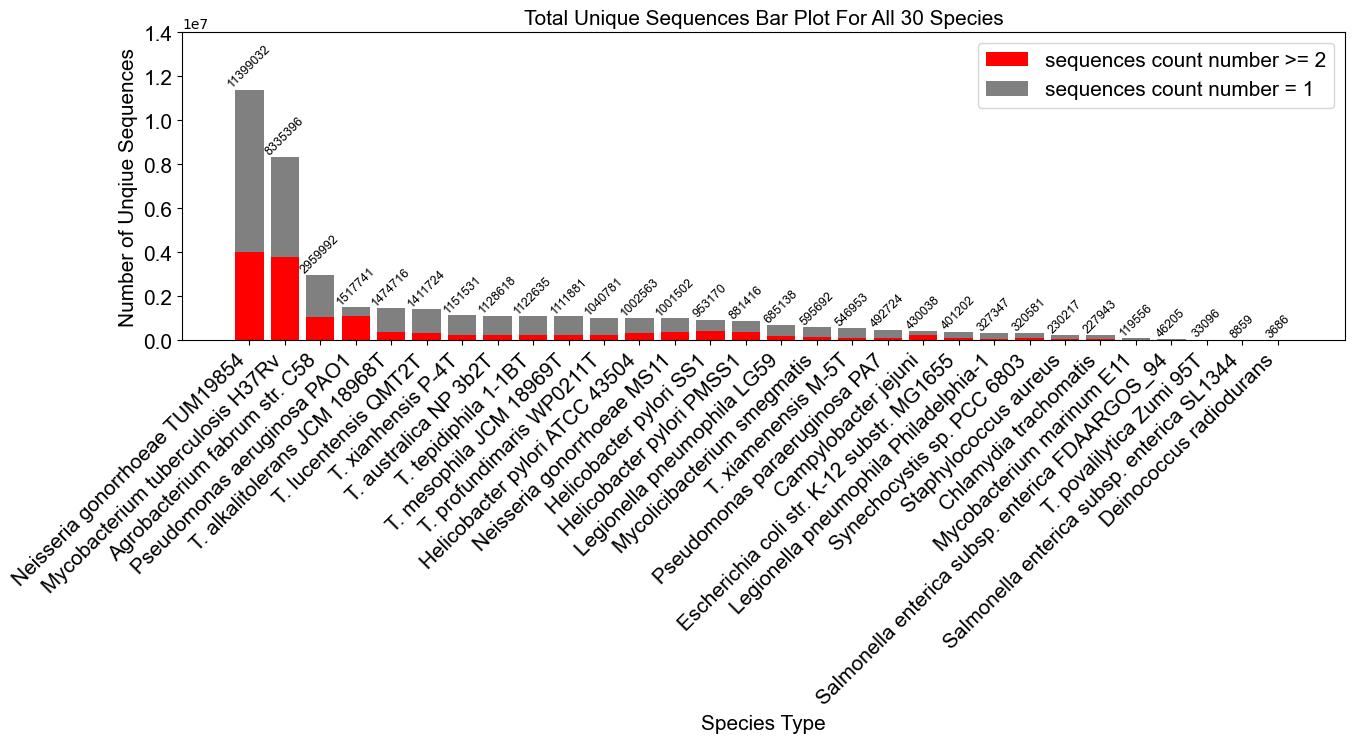

In [21]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=15)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=9)

labels = ['Pseudomonas aeruginosa PAO1',
            'Pseudomonas paraeruginosa PA7',
            'Legionella pneumophila LG59',
            'Staphylococcus aureus',
            'Salmonella enterica subsp. enterica FDAARGOS_94',
            'Escherichia coli str. K-12 substr. MG1655',
            'Mycobacterium tuberculosis H37Rv',
            'T. xianhensis P-4T',
            'T. povalilytica Zumi 95T',
            'T. profundimaris WP0211T',
            'T. tepidiphila 1-1BT',
            'T. xiamenensis M-5T',
            'T. australica NP 3b2T',
            'T. alkalitolerans JCM 18968T',
            'T. lucentensis QMT2T',
            'T. mesophila JCM 18969T',
           'Agrobacterium fabrum str. C58',
            'Helicobacter pylori SS1',
            'Helicobacter pylori PMSS1',
            'Helicobacter pylori ATCC 43504',
            'Neisseria gonorrhoeae MS11',
            'Mycobacterium marinum E11',
            'Mycolicibacterium smegmatis',
            'Chlamydia trachomatis',
            'Campylobacter jejuni',
            'Deinococcus radiodurans',
            'Salmonella enterica subsp. enterica SL1344',
            'Synechocystis sp. PCC 6803',
            'Neisseria gonorrhoeae TUM19854',
            'Legionella pneumophila Philadelphia-1']
# labels = ['A', 'B', 'C']
# Example data (3 bars, each split into 2 parts)
part_total = [1517741,
                492724,
                685138,
                230217,
                46205,
                401202,
                8335396,
                1151531,
                33096,
                1040781,
                1122635,
                546953,
                1128618,
                1474716,
                1411724,
                1111881,
                2959992,
                953170,
                881416,
                1002563,
                1001502,
                119556,
                595692,
                227943,
                430038,
                3686,
                8859,
                320581,
                11399032,
                327347]
part_equal_1 = [396705,
                384228,
                497802,
                170632,
                37979,
                293437,
                4525875,
                890459,
                17762,
                775053,
                853330,
                454441,
                867221,
                1093155,
                1050160,
                879453,
                1876261,
                538982,
                494026,
                663332,
                621835,
                80007,
                435429,
                154829,
                198559,
                2997,
                7805,
                227767,
                7357566,
                254173

                ]
# part1 = [30, 40, 50]
# part2 = [20, 15, 35]
part1 = [a - b for a, b in zip(part_total, part_equal_1)]
part2 = part_equal_1
combined = list(zip(labels, part1, part2, part_total))
combined_sorted = sorted(combined, key=lambda x: x[3], reverse=True)


labels_sorted  = [x[0] for x in combined_sorted]
part1_sorted   = [x[1] for x in combined_sorted]
part2_sorted   = [x[2] for x in combined_sorted]
part_total_sorted = [x[3] for x in combined_sorted]

x = np.arange(len(labels_sorted))

fig, ax = plt.subplots(figsize=(15,4))
color1 = "red"   # blue
color2 = "gray"   # orange

bars1 = plt.bar(x, part1_sorted, label='sequences count number >= 2', color=color1)


bars2 = plt.bar(x, part2_sorted, bottom=part1_sorted, label='sequences count number = 1', color=color2)
for i in range(len(x)):
    # total = part1[i] + part2[i]
    total = part_total_sorted[i]
    plt.text(
        x[i], total + 1,          
        str(total), 
        ha='center', rotation=45, va='bottom',
        fontproperties=arial_font_in
    )
plt.yticks(fontproperties=arial_font)
ax.set_xlabel('Species Type', fontproperties=arial_font)
ax.set_ylabel('Number of Unqiue Sequences',fontproperties=arial_font)
ax.set_title('Total Unique Sequences Bar Plot For All 30 Species' ,fontproperties=arial_font)
ax.margins(x=0.05)
ax.set_ylim(0, 14 *1e6)  
ax.legend(prop=arial_font,
title_fontproperties=arial_font)

plt.xticks(x, labels_sorted, rotation=45, ha='right', fontproperties=arial_font)
plt.savefig("figure_last_2.pdf", format="pdf", bbox_inches="tight")